# Rossmann Retail Demand Forecasting

## Problem Framing

### Problem Statement
Rossmann store managers need to know how much each store will sell in the coming days to plan staffing and stock. A forecast that is too low means lost sales. One that is too high means waste and tied-up cash.

### Task
Supervised regression: predict `Sales` (euros) for each store and day, for the next 7 days. One model with lag features at least 7 days back (lags 7, 14, 21, 28) is reused for each of the 7 forecast days.

### Metrics
- **WAPE** (total absolute error divided by total sales) is the headline metric.
- **MAE** in euros is reported alongside it.
- A model must beat two baselines: sales on the same weekday last week, and the store's average for that weekday.
- Closed days (`Open = 0`) are dropped from training and scoring. Their `Sales` is always 0 because of the store schedule, not demand, and they would pull MAE down. At prediction time, a closed store gets a forecast of 0.



### Validation plan
- Three rolling backtest folds, each trained only on earlier data, are used to compare and tune models.
- The last 6 weeks of `train.csv` are a final holdout, scored once. (Kaggle's `test.csv` has no `Sales`, so it isn't used.)
- Only things known before the day starts are used for the forecast days: `Open` (store schedule), `Promo`, `StateHoliday` and `SchoolHoliday` are all planned in advance. Same-day `Customers` is not, so it is not used as a feature. That would be data leakage.


## Setup

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf


# Constants
HORIZON = 7          # forecast days ahead
HOLDOUT_DAYS = 42    # final holdout: the last 6 weeks of train.csv
RANDOM_SEED = 1      # reproducible randomness

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## Data Preparation

### Load data

- `train.csv` has one row per store per day.
- `store.csv` has one row per store. 
- `StateHoliday` is read as text because it mixes numbers and letters.

In [2]:
train = pd.read_csv(
    "../data/raw/train.csv",
    dtype={"StateHoliday": "str"},
    parse_dates=["Date"],
)

print(f"train: {train.shape[0]:,} rows x {train.shape[1]} columns")

train: 1,017,209 rows x 9 columns


In [3]:
store = pd.read_csv("../data/raw/store.csv")

print(f"store: {store.shape[0]:,} rows x {store.shape[1]} columns")

store: 1,115 rows x 10 columns


### Data Profiling

Checking the raw data before changing anything.

- Structure and types
- Date range
- Grain (duplicates) check
- Completeness check
- Missing data, range and value checks
- Target (`Sales`)
- Findings

#### Structure and types

Preview first few rows and check each column's info (non-null counts, data types)

In [4]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [5]:
train.tail()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1
1017208,1115,2,2013-01-01,0,0,0,0,a,1


The rows are sorted newest first (2015-07-31 down to 2013-01-01), and within each date by `Store`. Lags and rolling features need oldest-to-newest order, so cleaning sorts by `Store` and `Date`.

In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  str           
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), str(1)
memory usage: 69.8 MB


**Data Dictionary**

`train.csv` (one row per store per day)

| Column | Meaning |
|---|---|
| `Store` | Store ID, 1 to 1,115 |
| `Date` | Calendar day |
| `DayOfWeek` | 1 = Monday to 7 = Sunday |
| `Sales` | Turnover in euros that day (**target**) |
| `Customers` | Number of customers that day |
| `Open` | 0 = closed, 1 = open |
| `Promo` | Whether the store ran a promotion that day |
| `StateHoliday` | Public holiday type: `0` none, `a` public, `b` Easter, `c` Christmas |
| `SchoolHoliday` | Whether the store was affected by school closures |

In [7]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [8]:
store.info()

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 87.2 KB


**Data Dictionary**

`store.csv` (one row per store)

| Column | Meaning |
|---|---|
| `StoreType` | Store model, `a` to `d` |
| `Assortment` | Product range level: `a` basic, `b` extra, `c` extended |
| `CompetitionDistance` | Distance in metres to the nearest competitor |
| `CompetitionOpenSinceMonth`, `CompetitionOpenSinceYear` | When the nearest competitor opened |
| `Promo2` | Whether the store takes part in a continuing promotion (0 or 1) |
| `Promo2SinceWeek`, `Promo2SinceYear` | When the store joined that promotion |
| `PromoInterval` | Months when a Promo2 round restarts, e.g. `Feb,May,Aug,Nov` |

#### Date range

In [9]:
earliest_date = train["Date"].min()
latest_date = train["Date"].max()
days = (latest_date - earliest_date).days + 1
years = days / 365

print(f"Earliest date: {earliest_date.date()}")
print(f"Latest date: {latest_date.date()}")
print(f"Number of days: {days}")
print(f"Number of years: {years:.2f}")

Earliest date: 2013-01-01
Latest date: 2015-07-31
Number of days: 942
Number of years: 2.58


#### Grain check

Used to spot potential duplicates in our data

In [10]:
print(f"Number of duplicate rows: {train.duplicated(['Store', 'Date']).sum()}")

Number of duplicate rows: 0


#### Completeness check

Every store should have one row for every day, so 1,115 stores × 942 days. Missing rows matter because lags are built from dates, and a gap breaks any "7 rows back" shortcut.

In [11]:
n_stores = train["Store"].nunique()
expected_rows = n_stores * days
missing_rows = expected_rows - len(train)
missing_per_store = days - train.groupby("Store").size()

print(f"Expected rows (stores x days): {expected_rows:,}")
print(f"Actual rows: {len(train):,}")
print(f"Missing store-days: {missing_rows:,} ({missing_rows / expected_rows:.1%})")
print(f"Stores with gaps: {(missing_per_store > 0).sum()} of {n_stores}")
print(f"Worst store is missing {missing_per_store.max()} days")

Expected rows (stores x days): 1,050,330
Actual rows: 1,017,209
Missing store-days: 33,121 (3.2%)
Stores with gaps: 181 of 1115
Worst store is missing 184 days


33,121 store-days (about 3%) have no row at all. 181 stores have gaps, and the worst is missing 184 days. These are likely temporary closures, which EDA will check. Lags and rolling features must be built by calendar date, never by row position.

#### Missing data, range and value checks

**Train**

In [12]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [13]:
train[["Sales", "Customers"]].describe()

,Sales,Customers
count,1.017209e+06,1.017209e+06
mean,5.773819e+03,6.331459e+02
std,3.849926e+03,4.644117e+02
min,0.000000e+00,0.000000e+00
25%,3.727000e+03,4.050000e+02
50%,5.744000e+03,6.090000e+02
75%,7.856000e+03,8.370000e+02
max,4.155100e+04,7.388000e+03


In [14]:
for col in ["DayOfWeek", "Open", "Promo", "StateHoliday", "SchoolHoliday"]:
    print(train[col].value_counts(dropna=False).sort_index(), "\n")

DayOfWeek
1    144730
2    145664
3    145665
4    145845
5    145845
6    144730
7    144730
Name: count, dtype: int64 

Open
0    172817
1    844392
Name: count, dtype: int64 

Promo
0    629129
1    388080
Name: count, dtype: int64 

StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: int64 

SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64 



**train:** no missing values, and all categorical columns contain only expected values (flags are 0/1, `StateHoliday` is `0`/`a`/`b`/`c`). `Sales` and `Customers` have no negatives, but both have a minimum of 0, likely the 172,817 closed days (`Open = 0`). The Target section checks this. Both are also right-skewed (max `Sales` 41,551 vs mean about 5,774), which EDA will examine. `StateHoliday` stores "no holiday" as `0` next to the letter codes, so it needs recoding in cleaning.

**Store**

In [15]:
store.isnull().sum()

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

In [16]:
store.describe()

,Store,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1115.00000,1112.000000,761.000000,761.000000,1115.000000,571.000000,571.000000
mean,558.00000,5404.901079,7.224704,2008.668857,0.512108,23.595447,2011.763573
std,322.01708,7663.174720,3.212348,6.195983,0.500078,14.141984,1.674935
min,1.00000,20.000000,1.000000,1900.000000,0.000000,1.000000,2009.000000
25%,279.50000,717.500000,4.000000,2006.000000,0.000000,13.000000,2011.000000
50%,558.00000,2325.000000,8.000000,2010.000000,1.000000,22.000000,2012.000000
75%,836.50000,6882.500000,10.000000,2013.000000,1.000000,37.000000,2013.000000
max,1115.00000,75860.000000,12.000000,2015.000000,1.000000,50.000000,2015.000000


In [17]:
store["CompetitionOpenSinceYear"].nsmallest(3)

814    1900.0
145    1961.0
328    1990.0
Name: CompetitionOpenSinceYear, dtype: float64

In [18]:
for col in ["StoreType", "Assortment", "PromoInterval"]:
    print(store[col].value_counts(dropna=False).sort_index(), "\n")

StoreType
a    602
b     17
c    148
d    348
Name: count, dtype: int64 

Assortment
a    593
b      9
c    513
Name: count, dtype: int64 

PromoInterval
Feb,May,Aug,Nov     130
Jan,Apr,Jul,Oct     335
Mar,Jun,Sept,Dec    106
NaN                 544
Name: count, dtype: int64 



**store:** the missing data has clear causes.

- `Promo2SinceWeek`, `Promo2SinceYear` and `PromoInterval` are missing for 544 stores, which matches the 544 stores with `Promo2 = 0`. These stores aren't in the Promo2 programme, so the values are structurally absent, not unknown.
- `CompetitionOpenSinceMonth` and `CompetitionOpenSinceYear` are missing for 354 stores (32%), and `CompetitionDistance` for 3 stores. How to fill them is decided in cleaning.

Ranges are plausible except `CompetitionOpenSinceYear`, where one store has 1900, far below the next lowest year (1961). It is treated as an outlier and handled in cleaning.

`CompetitionDistance` is right-skewed (median about 2,325 m, max 75,860 m). Categories are consistent: `StoreType` (a to d), `Assortment` (a to c) and three `PromoInterval` patterns. `PromoInterval` spells September as "Sept", which matters when parsing months.

#### Target (`Sales`)

Is `Sales = 0` the same as a closed store (`Open = 0`)? Zero sales on an open day would be suspicious.

In [19]:
pd.crosstab(
    train["Sales"].eq(0).map({True: "Sales = 0", False: "Sales > 0"}),
    train["Open"].map({0: "Closed", 1: "Open"}),
    rownames=["Sales"],
    colnames=["Store status"],
)

Store status,Closed,Open
Sales,,
Sales = 0,172817,54
Sales > 0,0,844338


#### Findings

- **Row order:** `train` is sorted newest first. Cleaning sorts by `Store` and `Date` before any lag or rolling feature is built.
- **Grain:** one row per store per day, no duplicates. `train` covers 1,115 stores from 2013-01-01 to 2015-07-31.
- **Completeness:** 33,121 of 1,050,330 store-days (about 3%) have no row. 181 stores have gaps, the worst missing 184 days. Lags must be built by calendar date, not row position.
- **Missing data:** `train` has none. In `store`, the Promo2 fields are missing for the 544 stores not in Promo2 (structural). The competition fields are missing for 354 stores (unknown), and `CompetitionDistance` for 3.
- **Target:** closed days always have `Sales = 0`. 54 open days also have zero sales, so cleaning decides what to do with them.
- **Suspicious values:** one store has `CompetitionOpenSinceYear = 1900`, far below the next lowest year (1961). It is an outlier, handled in cleaning.
- **Formatting issues:** `StateHoliday` mixes `0` with letter codes, and `PromoInterval` spells September as "Sept".
- **Skew:** `Sales`, `Customers` and `CompetitionDistance` are right-skewed, to be examined in EDA.

### Data cleaning

Fixing the problems found in profiling, on copies of the raw tables. Each fix adds one line to the cleaning log.

- Create copies and setup cleaning log
- Column names, formatting, and date order
- Store missing values and outliers
- Zero sales and closed days
- Validation checks
- Cleaning log and findings


#### Create copies and the setup cleaning log

Fixes are made on copies (`train_clean`, `store_clean`). The raw `train` and `store` tables stay untouched, so we can always compare before and after. Each fix adds one line to the cleaning log: issue, fix, why.

In [20]:
train_clean = train.copy()
store_clean = store.copy()

print(f"train_clean: {train_clean.shape[0]:,} rows x {train_clean.shape[1]} columns")
print(f"store_clean: {store_clean.shape[0]:,} rows x {store_clean.shape[1]} columns")

train_clean: 1,017,209 rows x 9 columns
store_clean: 1,115 rows x 10 columns


In [21]:
cleaning_log = []

In [22]:
def log_fix(issue, fix, why):
    """Add one line to the cleaning log. Re-running a cell updates its line, not adds a copy."""
    entry = {"issue": issue, "fix": fix, "why": why}
    for i, row in enumerate(cleaning_log):
        if row["issue"] == issue:
            cleaning_log[i] = entry
            return
    cleaning_log.append(entry)


#### Column names, formatting, and date order


Rename the columns to snake_case. The key `Store` becomes `store_id`, so it is not confused with the `store` table.

In [23]:
def to_snake_case(name):
    """StateHoliday -> state_holiday, Promo2SinceWeek -> promo2_since_week."""
    return re.sub(r"(?<=[a-z0-9])(?=[A-Z])", "_", name).lower()

In [24]:
train_clean = train_clean.rename(columns=to_snake_case).rename(columns={"store": "store_id"})
store_clean = store_clean.rename(columns=to_snake_case).rename(columns={"store": "store_id"})

log_fix(
    issue="Column names are PascalCase",
    fix="Renamed all columns in both tables to snake_case",
    why="One consistent style that is easy to type and read",
)
log_fix(
    issue="Key column `Store` has the same name as the `store` table",
    fix="Renamed it to `store_id` in both tables",
    why="Clearer in code and as the merge key",
)

for name, raw_df, clean_df in [("train", train, train_clean), ("store", store, store_clean)]:
    print(name)
    for raw_col, clean_col in zip(raw_df.columns, clean_df.columns):
        print(f"  {raw_col:<28} -> {clean_col}")


train
  Store                        -> store_id
  DayOfWeek                    -> day_of_week
  Date                         -> date
  Sales                        -> sales
  Customers                    -> customers
  Open                         -> open
  Promo                        -> promo
  StateHoliday                 -> state_holiday
  SchoolHoliday                -> school_holiday
store
  Store                        -> store_id
  StoreType                    -> store_type
  Assortment                   -> assortment
  CompetitionDistance          -> competition_distance
  CompetitionOpenSinceMonth    -> competition_open_since_month
  CompetitionOpenSinceYear     -> competition_open_since_year
  Promo2                       -> promo2
  Promo2SinceWeek              -> promo2_since_week
  Promo2SinceYear              -> promo2_since_year
  PromoInterval                -> promo_interval


`state_holiday` mixes `0` with the letter codes, and `promo_interval` spells September as "Sept" while every other month uses three letters. Both are recoded so the values are readable and month matching works.

In [25]:
def recode_categories(df, column, labels):
    """Return a copy of df with `column` recoded through the `labels` dict.

    Safe to re-run: if every value is already a label, the data is returned unchanged.
    Raises ValueError for unknown codes, or for a mix of old and new codes.
    Missing values stay missing.
    """
    codes = set(df[column].dropna().unique())
    if codes <= set(labels):
        return df.assign(**{column: df[column].map(labels)})
    if codes <= set(labels.values()):
        return df  # already recoded, nothing to do
    unexpected = codes - set(labels) - set(labels.values())
    if unexpected:
        raise ValueError(f"Unexpected codes in {column!r}: {sorted(unexpected)}")
    raise ValueError(f"{column!r} is partly recoded (a mix of old and new codes)")


In [26]:
def fix_spelling(df, column, corrections):
    """Return a copy of df with each wrong spelling in `corrections` fixed inside `column`.

    `corrections` maps wrong -> right, for example {"Sept": "Sep"}. It matches text
    inside a value, not only whole values, and the match is literal (no regex).
    Missing values stay missing.
    """
    fixed = df[column]
    for wrong, right in corrections.items():
        fixed = fixed.str.replace(wrong, right, regex=False)
    return df.assign(**{column: fixed})

In [27]:
HOLIDAY_LABELS = {
    "0": "none", 
    "a": "public", 
    "b": "easter", 
    "c": "christmas"
}

train_clean = recode_categories(train_clean, "state_holiday", HOLIDAY_LABELS)

log_fix(
    issue="`StateHoliday` mixes `0` with the letter codes a, b, and c",
    fix="Recoded to readable labels: none, public, easter, christmas",
    why="Clear labels in plots and features, with no number next to letters",
)

print(train_clean["state_holiday"].value_counts(), "\n")

state_holiday
none         986159
public        20260
easter         6690
christmas      4100
Name: count, dtype: int64 



In [28]:
PROMO_INTERVAL_FIXES = {"Sept": "Sep"}

store_clean = fix_spelling(store_clean, "promo_interval", PROMO_INTERVAL_FIXES)

log_fix(
    issue='`PromoInterval` spells September as "Sept"',
    fix='Replaced "Sept" with "Sep"',
    why="Matches the three-letter abbreviation of the other months, so month matching works",
)

print(store_clean["promo_interval"].value_counts(dropna=False))

promo_interval
NaN                544
Jan,Apr,Jul,Oct    335
Feb,May,Aug,Nov    130
Mar,Jun,Sep,Dec    106
Name: count, dtype: int64


`assortment` has a documented meaning for each code, so it is recoded to words.

In [29]:
ASSORTMENT_LABELS = {
    "a": "basic",
    "b": "extra",
    "c": "extended",
}

store_clean = recode_categories(store_clean, "assortment", ASSORTMENT_LABELS)

log_fix(
    issue="`Assortment` uses the codes a, b, and c",
    fix="Recoded to basic, extra, and extended, as in the data dictionary",
    why="Readable plots and features. `StoreType` keeps its letters because the dictionary gives them no meaning",
)

print(store_clean["assortment"].value_counts(), "\n")

assortment
basic       593
extended    513
extra         9
Name: count, dtype: int64 



`store_type` has no documented meaning, so it keeps its letters.

In [30]:
print(store_clean["store_type"].value_counts().sort_index())

store_type
a    602
b     17
c    148
d    348
Name: count, dtype: int64


Sort `train_clean` by `store_id` and `date`, oldest first. Rolling features need each store's days in time order. Lags are still built by calendar date, not row position.


In [31]:
def sort_rows(df, by):
    """Return a copy of df sorted by the columns in `by` (oldest first), with a fresh row index.

    Safe to re-run: sorting already-sorted data changes nothing.
    """
    return df.sort_values(by).reset_index(drop=True)

In [32]:
SORT_KEYS = ["store_id", "date"]

train_clean = sort_rows(train_clean, SORT_KEYS)

log_fix(
    issue="`train` is sorted newest first",
    fix="Sorted by `store_id` and `date`, oldest first, and reset the row index",
    why="Rolling features need each store's days in time order, and the row order is the same on every run",
)

display(train_clean[["store_id", "date", "sales"]].head(3))
display(train_clean[["store_id", "date", "sales"]].tail(3))
print(f"rows: {len(train_clean):,}")


,store_id,date,sales
0,1,2013-01-01,0
1,1,2013-01-02,5530
2,1,2013-01-03,4327


,store_id,date,sales
1017206,1115,2015-07-29,7661
1017207,1115,2015-07-30,8405
1017208,1115,2015-07-31,8680


rows: 1,017,209


#### Store missing values and outliers

Store 815 has a competition opening date of January 1900, far below the next lowest year (1961). It could be a very old competitor, but January 1900 is also a typical spreadsheet default date, so it is probably a placeholder. This cannot be proven, so the date is treated as unreliable and set to missing. The store itself stays. The effect is small: one store out of 1,115.

In [33]:
store_clean.nsmallest(3, "competition_open_since_year")

,store_id,store_type,assortment,competition_distance,competition_open_since_month,competition_open_since_year,promo2,promo2_since_week,promo2_since_year,promo_interval
814,815,a,basic,590.0,1.0,1900.0,1,40.0,2014.0,"Jan,Apr,Jul,Oct"
145,146,d,extended,8050.0,10.0,1961.0,1,48.0,2012.0,"Jan,Apr,Jul,Oct"
328,329,a,basic,1310.0,6.0,1990.0,1,22.0,2012.0,"Mar,Jun,Sep,Dec"


In [34]:
def set_missing(df, columns, where):
    """Return a copy of df with `columns` set to missing on the rows where `where` is True.

    Safe to re-run: rows that are already missing never match the condition.
    """
    fixed = df.copy()
    fixed.loc[where, columns] = float("nan")
    return fixed

In [35]:
MIN_PLAUSIBLE_YEAR = 1950
OPEN_SINCE_COLUMNS = ["competition_open_since_year", "competition_open_since_month"]

too_early = store_clean["competition_open_since_year"] < MIN_PLAUSIBLE_YEAR
store_clean = set_missing(store_clean, OPEN_SINCE_COLUMNS, too_early)

log_fix(
    issue="One store has `CompetitionOpenSinceYear` = 1900",
    fix="Set the year and month to missing for that store",
    why="January 1900 looks like a spreadsheet default date and is far below the next lowest year (1961). It cannot be verified, so it is treated as unreliable",

)

print(f"year missing: {store_clean['competition_open_since_year'].isna().sum()} | month missing: {store_clean['competition_open_since_month'].isna().sum()}")
print(f"lowest year now: {store_clean['competition_open_since_year'].min():.0f}")


year missing: 355 | month missing: 355
lowest year now: 1961


Three stores (291, 622, and 879) have no `competition_distance` and no opening date, so there is no competitor information for them at all. It is unknown whether they have no nearby competitor or the data was never recorded. They are filled with the median distance, which makes them look like a typical store. The effect is small: 3 stores out of 1,115.

In [36]:
display(store_clean[store_clean["competition_distance"].isna()])

,store_id,store_type,assortment,competition_distance,competition_open_since_month,competition_open_since_year,promo2,promo2_since_week,promo2_since_year,promo_interval
290,291,d,basic,NaN,NaN,NaN,0,NaN,NaN,NaN
621,622,a,extended,NaN,NaN,NaN,0,NaN,NaN,NaN
878,879,d,basic,NaN,NaN,NaN,1,5.0,2013.0,"Feb,May,Aug,Nov"


In [37]:
def fill_missing(df, column, value):
    """Return a copy of df with missing values in `column` replaced by `value`.

    Safe to re-run: once nothing is missing, nothing changes.
    """
    return df.assign(**{column: df[column].fillna(value)})

In [38]:
median_distance = store_clean["competition_distance"].median()
store_clean = fill_missing(store_clean, "competition_distance", median_distance)

log_fix(
    issue="3 stores have no `CompetitionDistance`",
    fix=f"Filled with the median distance ({median_distance:,.0f} m)",
    why="Only 3 of 1,115 stores. The median keeps them looking like a typical store and does not claim there is no competitor, which we cannot know",
)

print(f"distance missing: {store_clean['competition_distance'].isna().sum()} | filled value: {median_distance:,.0f} m")

distance missing: 0 | filled value: 2,325 m


The competition opening date is split into a year column and a month column. They are combined into one date (the first day of the month), and the two originals are dropped. 355 stores have no date (354 unknown, plus the 1900 outlier). They stay missing, because we do not invent dates.

In [39]:
def combine_year_month(df, new_col, year, month, day=1):
    """Return a copy of df with a year column and a month column combined into one date column `new_col`.

    `day` is a fixed day of the month. The source columns are dropped.
    A missing year or month gives a missing date.
    Safe to re-run: if `new_col` exists and the source columns are gone, df is returned unchanged.
    """
    source_cols = [year, month]
    if new_col in df.columns and not any(c in df.columns for c in source_cols):
        return df
    dates = pd.to_datetime({"year": df[year], "month": df[month], "day": day}, errors="coerce")
    return df.drop(columns=source_cols).assign(**{new_col: dates})


In [40]:
store_clean = combine_year_month(
    store_clean,
    new_col="competition_open_since",
    year="competition_open_since_year",
    month="competition_open_since_month",
)

log_fix(
    issue="Competition opening date is split across a year and a month column",
    fix="Combined into one date column `competition_open_since` (first day of the month) and dropped the two originals",
    why="One date is easy to compare with `date` when we work out how long a competitor has been open. Unknown dates stay missing",
)

open_since = store_clean["competition_open_since"]
print(f"missing: {open_since.isna().sum()} | earliest: {open_since.min().date()} | latest: {open_since.max().date()}")
print(f"store_clean columns: {store_clean.shape[1]}")


missing: 355 | earliest: 1961-10-01 | latest: 2015-08-01
store_clean columns: 9


`promo2_since_week`, `promo2_since_year`, and `promo_interval` are missing for exactly the 544 stores with `promo2 = 0`, so the gaps mean "not in the programme", not "unknown". `promo_interval` is filled with `none`.

In [41]:
promo2_columns = ["promo2_since_week", "promo2_since_year", "promo_interval"]

pd.crosstab(
    store_clean["promo2"],
    store_clean[promo2_columns].isna().all(axis=1),
    rownames=["promo2"],
    colnames=["all 3 fields missing"],
)

all 3 fields missing,False,True
promo2,,
0,0,544
1,571,0


In [42]:
store_clean = fill_missing(store_clean, "promo_interval", "none")

log_fix(
    issue="`PromoInterval` is missing for the 544 stores not in Promo2",
    fix='Filled with "none". The since-week and since-year fields stay missing',
    why="The gap means not in the programme, not unknown. An explicit category is clearer for encoders, and a fake start date would be wrong",
)

print(store_clean["promo_interval"].value_counts(dropna=False))


promo_interval
none               544
Jan,Apr,Jul,Oct    335
Feb,May,Aug,Nov    130
Mar,Jun,Sep,Dec    106
Name: count, dtype: int64


`promo2_since_week` and `promo2_since_year` are combined into one date, the Monday of that ISO week, so it can be compared with each row's `date`. 212 of the 571 Promo2 stores joined during our data period, so the start date tells the model when Promo2 began for them. The date stays missing for the 544 stores not in Promo2, because they have no start date. ISO weeks are an assumption (the German standard), and a different convention shifts dates by only a few days.

In [43]:
def combine_year_week(df, new_col, year, week, weekday=1):
    """Return a copy of df with a year and an ISO week combined into one date column `new_col`.

    ISO 8601 weeks (the German standard): week 1 is the week with the first Thursday of the year.
    `weekday` picks the day of that week, 1 = Monday ... 7 = Sunday. The source columns are dropped.
    A missing year or week gives a missing date.
    Safe to re-run: if `new_col` exists and the source columns are gone, df is returned unchanged.
    """
    source_cols = [year, week]
    if new_col in df.columns and not any(c in df.columns for c in source_cols):
        return df
    jan4 = pd.to_datetime({"year": df[year], "month": 1, "day": 4}, errors="coerce")  # always in ISO week 1
    week1_start = jan4 - pd.to_timedelta(jan4.dt.day_of_week, unit="D")
    dates = week1_start + pd.to_timedelta((df[week] - 1) * 7 + (weekday - 1), unit="D")
    return df.drop(columns=source_cols).assign(**{new_col: dates})


In [44]:
store_clean = combine_year_week(
    store_clean,
    new_col="promo2_since",
    year="promo2_since_year",
    week="promo2_since_week",
)

log_fix(
    issue="Promo2 start is split across a week and a year column",
    fix="Combined into one date column `promo2_since` (Monday of the ISO week) and dropped the two originals. Missing for stores not in Promo2",
    why="One date is easy to compare with `date` when we build a Promo2 active feature. ISO weeks are an assumption, but a different convention shifts dates by only a few days",
)

promo2_since = store_clean["promo2_since"]
print(f"missing: {promo2_since.isna().sum()} | earliest: {promo2_since.min().date()} | latest: {promo2_since.max().date()}")
print(f"store_clean columns: {store_clean.shape[1]}")


missing: 544 | earliest: 2009-07-27 | latest: 2015-06-01
store_clean columns: 8


#### Zero sales and closed days

54 open days (`open = 1`) have `sales = 0`, in 41 stores. On 52 of them `customers` is also 0, and the same stores trade normally a week before and after, so these are most likely unrecorded closures or data glitches, not real quiet days. A typical store has about 676 customers on an open day, and the lowest open day with any sales has 8. The other 2 (stores 948 and 1100) have only 3 to 5 customers. Zero sales on an open day is not a demand signal a model can learn, and it would corrupt the lag features, so all 54 rows are dropped. Lags are built by calendar date, so those dates become missing values, like the gap days.

In [45]:
zero_open = (train_clean["open"] == 1) & (train_clean["sales"] == 0)

display(train_clean[zero_open])
print(f"open days with zero sales: {zero_open.sum()} in {train_clean.loc[zero_open, 'store_id'].nunique()} stores")
print(f"customers == 0 on {(train_clean.loc[zero_open, 'customers'] == 0).sum()} of them")

,store_id,day_of_week,date,sales,customers,open,promo,state_holiday,school_holiday
22463,25,3,2014-02-12,0,0,1,0,none,0
22464,25,4,2014-02-13,0,0,1,0,none,0
25491,28,2,2014-09-02,0,0,1,1,none,1
25492,28,3,2014-09-03,0,0,1,1,none,1
25493,28,4,2014-09-04,0,0,1,1,none,0
51642,57,2,2014-07-01,0,0,1,1,none,0
92755,102,6,2014-07-12,0,0,1,0,none,0
92767,102,4,2014-07-24,0,0,1,0,none,1
205598,227,4,2014-09-11,0,0,1,0,none,0
209529,232,4,2013-01-24,0,0,1,1,none,0


open days with zero sales: 54 in 41 stores
customers == 0 on 52 of them


In [46]:
def drop_rows_where(df, condition):
    """Return a copy of df without the rows where `condition(df)` is True, with a fresh row index.

    `condition` is a function that takes the DataFrame and returns True or False per row, so it is
    always checked against the current data. Safe to re-run: once the rows are gone, nothing matches.
    """
    return df.loc[~condition(df)].reset_index(drop=True)

In [47]:
def is_zero_sales_open_day(df):
    return (df["open"] == 1) & (df["sales"] == 0)

In [48]:
rows_before = len(train_clean)
train_clean = drop_rows_where(train_clean, is_zero_sales_open_day)

log_fix(
    issue="54 open days have `Sales` = 0 (52 of them also have 0 customers)",
    fix="Dropped the 54 rows",
    why="Most likely an unrecorded closure or data glitch, since the same stores trade normally the weeks around it. Kept in, they would corrupt the lag features. The dates become missing values, like the gap days",
)

print(f"rows: {rows_before:,} -> {len(train_clean):,} | removed: {rows_before - len(train_clean)}")
print(f"open days with zero sales now: {is_zero_sales_open_day(train_clean).sum()}")


rows: 1,017,209 -> 1,017,155 | removed: 54
open days with zero sales now: 0


Closed days (`open = 0`) are 17% of the rows. All of them have `sales = 0` and `customers = 0`, so the zeros come from the store schedule, not from demand. 98% of Sundays are closed, and most of the rest are holidays. They are kept in the cleaned table, so EDA can show the patterns and lag features can use the full calendar. They are dropped when the model table is built, so they never reach training or scoring, and the API returns 0 when `open = 0`. Feature Engineering sets `sales` to missing on closed days before building lags, so a closed day never looks like a day with zero demand.

In [49]:
closed = train_clean[train_clean["open"] == 0]

print(f"closed days: {len(closed):,} ({len(closed) / len(train_clean):.1%} of {len(train_clean):,} rows)")
print(f"closed with sales > 0: {(closed['sales'] > 0).sum()} | closed with customers > 0: {(closed['customers'] > 0).sum()}")

by_weekday = pd.crosstab(train_clean["day_of_week"], train_clean["open"].map({0: "closed", 1: "open"}))
by_weekday["share_closed"] = (by_weekday["closed"] / (by_weekday["closed"] + by_weekday["open"])).map("{:.0%}".format)
by_weekday


closed days: 172,817 (17.0% of 1,017,155 rows)
closed with sales > 0: 0 | closed with customers > 0: 0


open,closed,open,share_closed
day_of_week,,,
1,7170,137557,5%
2,1703,143955,1%
3,3729,141922,3%
4,11201,134626,8%
5,7205,138633,5%
6,672,144052,0%
7,141137,3593,98%


#### Validation checks

Final checks on both cleaned tables before merging. Each check prints PASS or FAIL, and the cell stops with an error if any check fails. The checks only read the data, so they are safe to re-run. They cover:

- **Train:** unique, sorted rows, no missing values, `day_of_week` matches the date, closed days have zero sales and customers, open days have sales and customers above zero, known holiday labels, and the row count matches the raw table minus the dropped zero-sales days.
- **Store:** one row per store, missing values only in the two date columns, `promo2_since` missing exactly for stores not in Promo2, and a positive `competition_distance`.


In [50]:
def run_checks(checks):
    """Print PASS or FAIL for each (name, passed) pair, and raise if any check failed."""
    for name, passed in checks:
        print(f"{'PASS' if passed else 'FAIL'}  {name}")
    failed = [name for name, passed in checks if not passed]
    if failed:
        raise AssertionError(f"{len(failed)} check(s) failed: {failed}")


def train_checks(df, raw, holiday_labels):
    """Checks for the cleaned train table. `raw` is the untouched train table."""
    dropped = ((raw["Open"] == 1) & (raw["Sales"] == 0)).sum()
    is_open = df["open"] == 1
    return [
        ("no duplicate store-date rows", not df.duplicated(["store_id", "date"]).any()),
        ("sorted by store_id, then date", pd.MultiIndex.from_frame(df[["store_id", "date"]]).is_monotonic_increasing),
        ("no missing values", not df.isna().any().any()),
        ("day_of_week matches the date", ((df["date"].dt.day_of_week + 1) == df["day_of_week"]).all()),
        ("closed days have zero sales and zero customers", df.loc[~is_open, ["sales", "customers"]].eq(0).all().all()),
        ("open days have sales and customers above zero", (df.loc[is_open, ["sales", "customers"]] > 0).all().all()),
        ("state_holiday has only the known labels", df["state_holiday"].isin(holiday_labels.values()).all()),
        ("row count = raw rows minus the dropped zero-sales days", len(df) == len(raw) - dropped),
    ]


def store_checks(df, raw):
    """Checks for the cleaned store table. `raw` is the untouched store table."""
    missing_ok = {"competition_open_since", "promo2_since"}
    return [
        ("one row per store, same count as raw", df["store_id"].is_unique and len(df) == len(raw)),
        ("only the two date columns have missing values", set(df.columns[df.isna().any()]) <= missing_ok),
        ("promo2_since is missing exactly when promo2 = 0", (df["promo2_since"].isna() == (df["promo2"] == 0)).all()),
        ("competition_distance is positive", (df["competition_distance"] > 0).all()),
    ]


In [51]:
print("train_clean")
run_checks(train_checks(train_clean, train, HOLIDAY_LABELS))


train_clean
PASS  no duplicate store-date rows
PASS  sorted by store_id, then date
PASS  no missing values
PASS  day_of_week matches the date
PASS  closed days have zero sales and zero customers
PASS  open days have sales and customers above zero
PASS  state_holiday has only the known labels
PASS  row count = raw rows minus the dropped zero-sales days


In [52]:
print("store_clean")
run_checks(store_checks(store_clean, store))

store_clean
PASS  one row per store, same count as raw
PASS  only the two date columns have missing values
PASS  promo2_since is missing exactly when promo2 = 0
PASS  competition_distance is positive


#### Cleaning log and findings

In [53]:
cleaning_log_table = pd.DataFrame(cleaning_log)
cleaning_log_table.index = cleaning_log_table.index + 1

with pd.option_context("display.max_colwidth", None):
    display(cleaning_log_table)

print(f"{len(cleaning_log_table)} fixes logged")
print(f"train_clean: {train_clean.shape[0]:,} rows x {train_clean.shape[1]} columns")
print(f"store_clean: {store_clean.shape[0]:,} rows x {store_clean.shape[1]} columns")

,issue,fix,why
1,Column names are PascalCase,Renamed all columns in both tables to snake_case,One consistent style that is easy to type and read
2,Key column `Store` has the same name as the `store` table,Renamed it to `store_id` in both tables,Clearer in code and as the merge key
3,"`StateHoliday` mixes `0` with the letter codes a, b, and c","Recoded to readable labels: none, public, easter, christmas","Clear labels in plots and features, with no number next to letters"
4,"`PromoInterval` spells September as ""Sept""","Replaced ""Sept"" with ""Sep""","Matches the three-letter abbreviation of the other months, so month matching works"
5,"`Assortment` uses the codes a, b, and c","Recoded to basic, extra, and extended, as in the data dictionary",Readable plots and features. `StoreType` keeps its letters because the dictionary gives them no meaning
6,`train` is sorted newest first,"Sorted by `store_id` and `date`, oldest first, and reset the row index","Rolling features need each store's days in time order, and the row order is the same on every run"
7,One store has `CompetitionOpenSinceYear` = 1900,Set the year and month to missing for that store,"January 1900 looks like a spreadsheet default date and is far below the next lowest year (1961). It cannot be verified, so it is treated as unreliable"
8,3 stores have no `CompetitionDistance`,"Filled with the median distance (2,325 m)","Only 3 of 1,115 stores. The median keeps them looking like a typical store and does not claim there is no competitor, which we cannot know"
9,Competition opening date is split across a year and a month column,Combined into one date column `competition_open_since` (first day of the month) and dropped the two originals,One date is easy to compare with `date` when we work out how long a competitor has been open. Unknown dates stay missing
10,`PromoInterval` is missing for the 544 stores not in Promo2,"Filled with ""none"". The since-week and since-year fields stay missing","The gap means not in the programme, not unknown. An explicit category is clearer for encoders, and a fake start date would be wrong"


12 fixes logged
train_clean: 1,017,155 rows x 9 columns
store_clean: 1,115 rows x 8 columns


#### Findings

- **Result:** `train_clean` has 1,017,155 rows and 9 columns, and `store_clean` has 1,115 rows and 8 columns. 12 fixes are logged, and all 12 validation checks pass.
- **Names and formats:** all columns are snake_case, and the key is `store_id`. `state_holiday` and `assortment` are recoded to words, "Sept" is fixed to "Sep", and `train_clean` is sorted by `store_id` and `date`, oldest first.
- **Dropped:** 54 open days with zero sales. Most likely they are unrecorded closures or data glitches. Those dates are now missing, like the gap days.
- **Store missing values:** one probable placeholder date (store 815, January 1900) is set to missing. The 3 missing distances (stores 291, 622, and 879) are filled with the median (2,325 m). This does not leak: distance is a static store attribute, and the median uses no sales or dates, so it is the same with or without the holdout. `promo_interval` is `none` for the 544 stores not in Promo2.
- **Combined date columns:** competition year and month are combined into `competition_open_since`, with 355 stores unknown and left missing. Promo2 week and year are combined into `promo2_since` (ISO weeks, an assumption), missing for the 544 stores not in Promo2.
- **Deliberately not changed:**
  - The 172,817 closed days stay in the table and are dropped when the model table is built.
  - The 33,121 missing store-days (plus the 54 dropped rows) stay as gaps, handled by calendar date.
  - `store_type` keeps its letters, because the data dictionary gives them no meaning.
  - `sales` and `customers` skew is for EDA.
- **Hand-offs to later sections:**
  - **EDA:** describe each `store_type` from the data (average sales, Sunday opening), and check whether the 180 stores return to normal sales after the 2014-07 to 2014-12 gap.
  - **Feature Engineering:** set `sales` to missing on closed days before building lags. "Months open" must be 0 or missing before a competitor opens (the latest date, 2015-08-01, is after the last sale), and capped for very old competitors. Build "Promo2 active" from `promo2_since` and `promo_interval` (212 of 571 Promo2 stores joined during our data). Encode `store_type`, `assortment`, `state_holiday`, and `promo_interval`.


### Merge the datasets and save

#### Merge

Each row of `train_clean` gets its store's attributes from `store_clean`, matched on `store_id`. The join is many-to-one (many days per store, one row per store), so the row count must not change. The merge stops with an error if a store key is duplicated in the store table, if any sales row has no matching store, or if the row count changes. The merged table is `merged`. Only the two date columns have missing values: `competition_open_since` on 324,087 rows (stores with an unknown date) and `promo2_since` on 508,016 rows (stores not in Promo2).

In [54]:
def merge_checked(left, right, on):
    """Left-join `right` onto `left` on the key `on`, and check that nothing was gained or lost.

    Raises ValueError if `right` has duplicate keys (many-to-one join), if a key in `left` has no
    match in `right`, or if the row count changes. The inputs are not modified, so re-running is safe.
    """
    merged = left.merge(right, on=on, how="left", validate="many_to_one", indicator=True)
    unmatched = (merged["_merge"] != "both").sum()
    if unmatched:
        raise ValueError(f"{unmatched:,} rows in `left` have no match in `right` on {on!r}")
    if len(merged) != len(left):
        raise ValueError(f"Row count changed: {len(left):,} -> {len(merged):,}")
    return merged.drop(columns="_merge")


def merged_checks(df, left, right, on):
    """Checks for the merged table. `left` and `right` are the two tables that went into it."""
    date_columns = {"competition_open_since", "promo2_since"}
    return [
        ("row count is the same as before the merge", len(df) == len(left)),
        ("every store in the store table has sales rows", set(right[on]) <= set(df[on])),
        ("column count = left + right - the key", df.shape[1] == left.shape[1] + right.shape[1] - 1),
        ("only the two date columns have missing values", set(df.columns[df.isna().any()]) <= date_columns),
    ]


In [55]:
merged = merge_checked(train_clean, store_clean, on="store_id")

print(f"train_clean: {train_clean.shape[0]:,} rows x {train_clean.shape[1]} columns")
print(f"store_clean: {store_clean.shape[0]:,} rows x {store_clean.shape[1]} columns")
print(f"merged df:   {merged.shape[0]:,} rows x {merged.shape[1]} columns\n")
run_checks(merged_checks(merged, train_clean, store_clean, on="store_id"))
print()
print(merged[["competition_open_since", "promo2_since"]].isna().sum().to_string())


train_clean: 1,017,155 rows x 9 columns
store_clean: 1,115 rows x 8 columns
merged df:   1,017,155 rows x 16 columns

PASS  row count is the same as before the merge
PASS  every store in the store table has sales rows
PASS  column count = left + right - the key
PASS  only the two date columns have missing values

competition_open_since    324087
promo2_since              508016


#### Save

In [56]:
CLEAN_PATH = Path("../data/processed/fct_store_day.csv")

merged.to_csv(CLEAN_PATH, index=False)

print(f"saved: {CLEAN_PATH} ({CLEAN_PATH.stat().st_size / 1e6:.0f} MB)")


saved: ../data/processed/fct_store_day.csv (81 MB)


#### Load

In [57]:
fct_store_day = pd.read_csv(
    CLEAN_PATH,
    parse_dates=["date", "competition_open_since", "promo2_since"]
)

print(f"reloaded: {fct_store_day.shape[0]:,} rows x {fct_store_day.shape[1]} columns")
print(f"identical to the merged table, values and dtypes: {fct_store_day.equals(merged)}")

reloaded: 1,017,155 rows x 16 columns
identical to the merged table, values and dtypes: True


In [58]:
fct_store_day.head()

,store_id,day_of_week,date,sales,customers,open,promo,state_holiday,school_holiday,store_type,assortment,competition_distance,promo2,promo_interval,competition_open_since,promo2_since
0,1,2,2013-01-01,0,0,0,0,public,1,c,basic,1270.0,0,none,2008-09-01,NaT
1,1,3,2013-01-02,5530,668,1,0,none,1,c,basic,1270.0,0,none,2008-09-01,NaT
2,1,4,2013-01-03,4327,578,1,0,none,1,c,basic,1270.0,0,none,2008-09-01,NaT
3,1,5,2013-01-04,4486,619,1,0,none,1,c,basic,1270.0,0,none,2008-09-01,NaT
4,1,6,2013-01-05,4997,635,1,0,none,1,c,basic,1270.0,0,none,2008-09-01,NaT


In [59]:
fct_store_day.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017155 entries, 0 to 1017154
Data columns (total 16 columns):
 #   Column                  Non-Null Count    Dtype         
---  ------                  --------------    -----         
 0   store_id                1017155 non-null  int64         
 1   day_of_week             1017155 non-null  int64         
 2   date                    1017155 non-null  datetime64[us]
 3   sales                   1017155 non-null  int64         
 4   customers               1017155 non-null  int64         
 5   open                    1017155 non-null  int64         
 6   promo                   1017155 non-null  int64         
 7   state_holiday           1017155 non-null  str           
 8   school_holiday          1017155 non-null  int64         
 9   store_type              1017155 non-null  str           
 10  assortment              1017155 non-null  str           
 11  competition_distance    1017155 non-null  float64       
 12  promo2                  1

## Exploratory Data Analysis

Looking for patterns and relationships in the cleaned table. Only the rows before the final holdout are used, so the holdout stays unseen.

- Scope and target
- Value ranges and missing values
- Promo effect by weekday
- Store types
- The 2014 gap block
- Time series analysis
- Feature importance
- Findings


### Scope and target

EDA uses only the rows before the final holdout, so the holdout stays unseen.


In [60]:
HOLDOUT_START = fct_store_day["date"].max() - pd.Timedelta(days=HOLDOUT_DAYS - 1)
eda_df = fct_store_day[fct_store_day["date"] < HOLDOUT_START].copy()

print(f"holdout starts:  {HOLDOUT_START.date()}")
print(f"EDA rows:        {len(eda_df):,} of {len(fct_store_day):,} ({len(eda_df) / len(fct_store_day):.1%})")
print(f"EDA date range:  {eda_df['date'].min().date()} to {eda_df['date'].max().date()}")


holdout starts:  2015-06-20
EDA rows:        970,325 of 1,017,155 (95.4%)
EDA date range:  2013-01-01 to 2015-06-19


We will now look at the shape of `sales` on open days.

           sales  log1p(sales)
count  804056.00     804056.00
mean     6954.82          8.76
std      3106.25          0.43
min        46.00          3.85
25%      4856.00          8.49
50%      6368.00          8.76
75%      8360.00          9.03
max     38722.00         10.56

skew: sales = 1.59, log1p(sales) = -0.11


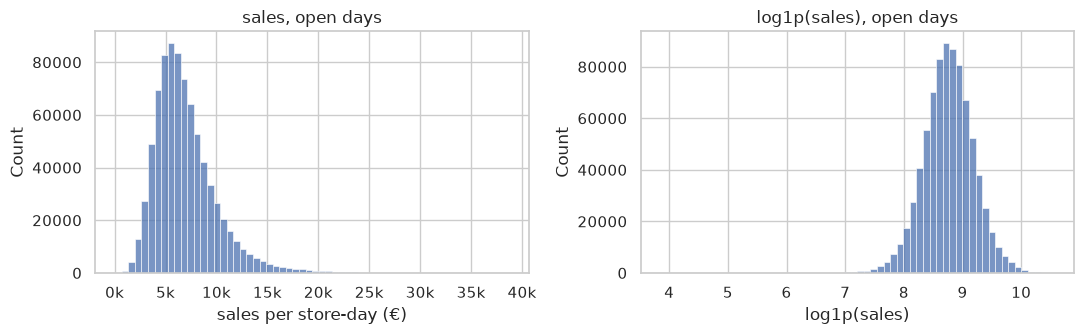

In [61]:
open_sales = eda_df.loc[eda_df["open"] == 1, "sales"]

summary = pd.DataFrame({
    "sales": open_sales.describe(),
    "log1p(sales)": np.log1p(open_sales).describe(),
})
print(summary.round(2))
print(f"\nskew: sales = {open_sales.skew():.2f}, log1p(sales) = {np.log1p(open_sales).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

sns.histplot(open_sales, bins=60, ax=axes[0])
axes[0].set_title("sales, open days")
axes[0].set_xlabel("sales per store-day (€)")
axes[0].xaxis.set_major_formatter(lambda x, _: f"{x / 1000:.0f}k")

sns.histplot(np.log1p(open_sales), bins=60, ax=axes[1])
axes[1].set_title("log1p(sales), open days")
axes[1].set_xlabel("log1p(sales)")

plt.tight_layout()
plt.show()


**Insight**

- EDA uses 970,325 rows (95.4%), from 2013-01-01 to 2015-06-19. The last 6 weeks stay unseen until the final score.
- Open-day `sales` is right-skewed: the mean (6,955) is above the median (6,368), and the skew is 1.59. 98% of open days fall between about 2,200 and 17,800, and only 0.5% are above 20,000, with a maximum of 38,722.
- `log1p` makes the shape close to symmetric (skew -0.11). It helps linear models like Ridge, and tree models do not need it. We decide in the backtest, and we always score in euros.
- A few very low days remain: 228 open days are under 1,000, as low as 46. That is 0.03% of open days, so we keep them and look again only if they hurt the errors.


### Value ranges and missing values

The cleaning checks proved the data is valid. Here we check that the values make sense for modelling, and see what is still empty.


Numerical variables

In [62]:
open_days = eda_df[eda_df["open"] == 1]
stores = eda_df.drop_duplicates("store_id")

ranges = pd.concat([
    open_days[["sales", "customers"]].describe().T,
    stores[["competition_distance"]].describe().T,
])
print(ranges[["count", "min", "25%", "50%", "75%", "max"]].round(0).astype("int64"))


                       count  min   25%   50%   75%    max
sales                 804056   46  4856  6368  8360  38722
customers             804056    8   520   677   895   7388
competition_distance    1115   20   720  2325  6875  75860


Categorical variables

In [63]:
value_columns = ["day_of_week", "open", "promo", "school_holiday", "state_holiday",
                 "store_type", "assortment", "promo2", "promo_interval"]
for column in value_columns:
    print(f"{column:15} {sorted(eda_df[column].unique().tolist())}")


day_of_week     [1, 2, 3, 4, 5, 6, 7]
open            [0, 1]
promo           [0, 1]
school_holiday  [0, 1]
state_holiday   ['christmas', 'easter', 'none', 'public']
store_type      ['a', 'b', 'c', 'd']
assortment      ['basic', 'extended', 'extra']
promo2          [0, 1]
promo_interval  ['Feb,May,Aug,Nov', 'Jan,Apr,Jul,Oct', 'Mar,Jun,Sep,Dec', 'none']


Missing values

In [64]:
missing = pd.DataFrame({
    "rows": eda_df.isna().sum(),
    "stores": stores.isna().sum(),
})
print(missing[missing["rows"] > 0])


                          rows  stores
competition_open_since  309177     355
promo2_since            485168     544


**Insight**

- All ranges are plausible. On open days, `sales` runs from 46 to 38,722 and `customers` from 8 to 7,388. Competition distance runs from 20 m to 75,860 m, with a median of 2,325 m.
- Distance is skewed: the top quarter of stores is above 6,875 m, and a few are very far out. Trees do not mind, but a log or a banding of distance is an option for Ridge.
- Flags are only 0 or 1, `day_of_week` is 1 to 7, and the categories hold only the cleaned labels, with no stray values.
- Only two columns have missing values, and both are expected. `competition_open_since` is unknown for 355 stores (31.8%). `promo2_since` is blank for 544 stores (48.8%), because they are not in Promo2.
- Both become features instead of being filled: "months open" and "Promo2 active".


### Promo effect by weekday

Does a promo lift sales, and is the lift the same on every weekday? We compare open days only.

In [65]:
weekday_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = open_days["date"].dt.day_name().str[:3].rename("weekday")

mean_sales = open_days.groupby([weekday, "promo"], as_index=False)["sales"].mean()

by_promo = mean_sales.pivot(index="weekday", columns="promo", values="sales").reindex(weekday_order)
promo_table = pd.DataFrame({
    "no_promo": by_promo[0].round(0),
    "promo": by_promo[1].round(0),
    "lift_pct": ((by_promo[1] / by_promo[0] - 1) * 100).round(1),
    "promo_share": open_days.groupby(weekday)["promo"].mean().round(2),
})
print(promo_table.reindex(weekday_order))


         no_promo   promo  lift_pct  promo_share
weekday                                         
Mon        6211.0  9762.0      57.2         0.56
Tue        5717.0  8247.0      44.2         0.54
Wed        5609.0  7678.0      36.9         0.54
Thu        5740.0  7595.0      32.3         0.55
Fri        6359.0  7734.0      21.6         0.52
Sat        5886.0     NaN       NaN         0.00
Sun        8208.0     NaN       NaN         0.00


`NaN` on Saturday and Sunday is correct, because there are no promo days to average

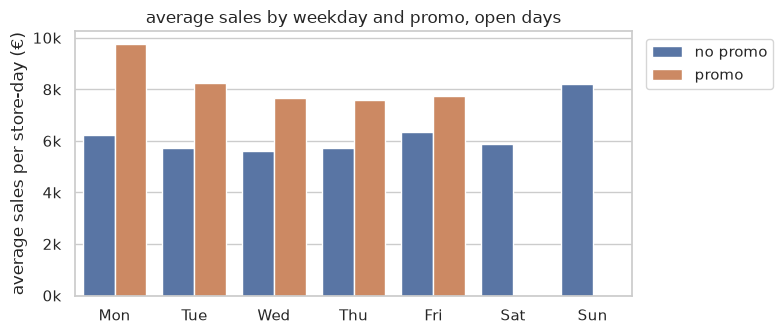

In [66]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(data=mean_sales, x="weekday", y="sales", hue="promo", order=weekday_order, ax=ax)
ax.set_title("average sales by weekday and promo, open days")
ax.set_xlabel("")
ax.set_ylabel("average sales per store-day (€)")
ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.0f}k")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["no promo", "promo"], loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()


Same-store check

In [67]:
weekdays_only = open_days[open_days["date"].dt.day_of_week < 5]

overall_means = weekdays_only.groupby("promo")["sales"].mean()
store_means = weekdays_only.groupby(["store_id", "promo"])["sales"].mean().unstack("promo")
store_lift = store_means[1] / store_means[0] - 1

print(f"overall lift, Mon to Fri:    {overall_means[1] / overall_means[0] - 1:.1%}")
print(f"median lift within a store:  {store_lift.median():.1%}")
print(f"stores with a positive lift: {(store_lift > 0).sum():,} of {store_lift.notna().sum():,}")


overall lift, Mon to Fri:    38.7%
median lift within a store:  39.2%
stores with a positive lift: 1,115 of 1,115


**Insight**

**Why it matters:** a promo is the biggest sales boost we can know in advance, and the size of the boost depends on the weekday, so the model needs both together.

- Promo days sell about 39% more than normal weekdays, and all 1,115 stores show it (median +39%), so it is not just bigger stores running more promos.
- The boost shrinks through the week: +57% on Monday, +22% on Friday. Promos run Monday to Friday only.
- Sunday's high average (8,208) comes from just 3,400 open store-days, about 31 stores, so it is not a typical Sunday.


### Store types
The data dictionary gives no meaning for the letters a to d, so we describe each type from the data: how many stores, how much they sell, who opens on Sundays, and which assortment they carry.


In [68]:
sunday_stores = open_days.loc[open_days["day_of_week"] == 7, "store_id"].unique()
store_profile = stores.set_index("store_id")[["store_type", "assortment"]].assign(
    avg_sales=open_days.groupby("store_id")["sales"].mean(),
    opens_sunday=lambda s: s.index.isin(sunday_stores),
)

by_type = open_days.groupby("store_type")
type_table = pd.DataFrame({
    "stores": store_profile.groupby("store_type").size(),
    "avg_sales": by_type["sales"].mean().round(0),
    "avg_customers": by_type["customers"].mean().round(0),
    "sunday_stores": store_profile.groupby("store_type")["opens_sunday"].sum(),
})
print(type_table)


            stores  avg_sales  avg_customers  sunday_stores
store_type                                                 
a              602     6928.0          797.0             13
b               17    10206.0         2016.0             17
c              148     6935.0          818.0              0
d              348     6814.0          607.0              3


In [69]:
print(pd.crosstab(store_profile["store_type"], store_profile["assortment"]))

assortment  basic  extended  extra
store_type                        
a             381       221      0
b               7         1      9
c              77        71      0
d             128       220      0


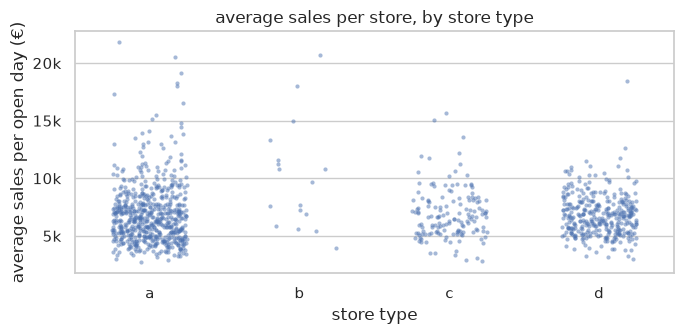

In [70]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.stripplot(data=store_profile, x="store_type", y="avg_sales", order=["a", "b", "c", "d"], size=3, alpha=0.5, jitter=0.25, ax=ax)
ax.set_title("average sales per store, by store type")
ax.set_xlabel("store type")
ax.set_ylabel("average sales per open day (€)")
ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.0f}k")
plt.tight_layout()
plt.show()


***Legend:** Each dot represents a store*

In [71]:
group_mean = store_profile.groupby("store_type")["avg_sales"].transform("mean")
spread_total = ((store_profile["avg_sales"] - store_profile["avg_sales"].mean()) ** 2).sum()
spread_left = ((store_profile["avg_sales"] - group_mean) ** 2).sum()
print(f"store_type explains {1 - spread_left / spread_total:.1%} of the differences between stores")

split_date = pd.Timestamp("2014-04-01")
before = open_days[open_days["date"] < split_date].groupby("store_id")["sales"].mean()
after = open_days[open_days["date"] >= split_date].groupby("store_id")["sales"].mean()
r = before.corr(after)
print(f"correlation of a store's average sales before and after {split_date.date()}: {r:.2f} ({r ** 2:.0%} explained)")

store_type explains 2.7% of the differences between stores
correlation of a store's average sales before and after 2014-04-01: 0.97 (95% explained)


**Insight**

**Why it matters:** the type letter will not tell the model how big a store is. A store's own sales history will, so lags and store averages matter more than `store_type`.

- Types a, c, and d sell the same, about 6,900 per open day. Type b is the exception: 48% higher, 2,016 customers a day, open on Sundays, and the only "extra" assortment. But it is just 17 stores.
- Across all stores, the type explains only 2.7% of the differences in sales levels.
- A store's average before and after 2014-04-01 correlates at 0.97 (95% explained). A store keeps its level.


### The 2014 gap block
180 stores have no rows from 2014-07-01 to 2014-12-31, and the data does not say why. Did they come back at the same sales level?


Find the closed stores

In [72]:
gap_start, gap_end = pd.Timestamp("2014-07-01"), pd.Timestamp("2014-12-31")

stores_with_rows_in_gap = eda_df.loc[eda_df["date"].between(gap_start, gap_end), "store_id"].unique()
gap_store_ids = stores.loc[~stores["store_id"].isin(stores_with_rows_in_gap), "store_id"]

gap_rows = eda_df[eda_df["store_id"].isin(gap_store_ids)]
print(f"stores with no rows from {gap_start.date()} to {gap_end.date()}: {len(gap_store_ids)}")
print(f"their last row before the gap: {gap_rows.loc[gap_rows['date'] < gap_start, 'date'].max().date()}")
print(f"their first row after the gap: {gap_rows.loc[gap_rows['date'] > gap_end, 'date'].min().date()}")


stores with no rows from 2014-07-01 to 2014-12-31: 180
their last row before the gap: 2014-06-30
their first row after the gap: 2015-01-01


Compare the same months a year apart

In [73]:
# average sales per open store-day, 1 January to 19 June of each year
windows = {"avg_2014": ("2014-01-01", "2014-06-19"), "avg_2015": ("2015-01-01", "2015-06-19")}
store_sales = pd.DataFrame({
    name: open_days[open_days["date"].between(start, end)].groupby("store_id")["sales"].mean()
    for name, (start, end) in windows.items()
})
store_sales["change_pct"] = (store_sales["avg_2015"] / store_sales["avg_2014"] - 1) * 100
store_sales["group"] = np.where(store_sales.index.isin(gap_store_ids), "gap stores", "other stores")

comparison = store_sales.groupby("group").agg(
    stores=("change_pct", "size"),
    avg_2014=("avg_2014", "mean"),
    avg_2015=("avg_2015", "mean"),
    median_store_pct=("change_pct", "median"),
)
comparison["change_pct"] = (comparison["avg_2015"] / comparison["avg_2014"] - 1) * 100
print(comparison[["stores", "avg_2014", "avg_2015", "change_pct", "median_store_pct"]].round(1))


              stores  avg_2014  avg_2015  change_pct  median_store_pct
group                                                                 
gap stores       180    6614.4    6883.4         4.1               4.1
other stores     935    6927.6    7149.1         3.2               3.6


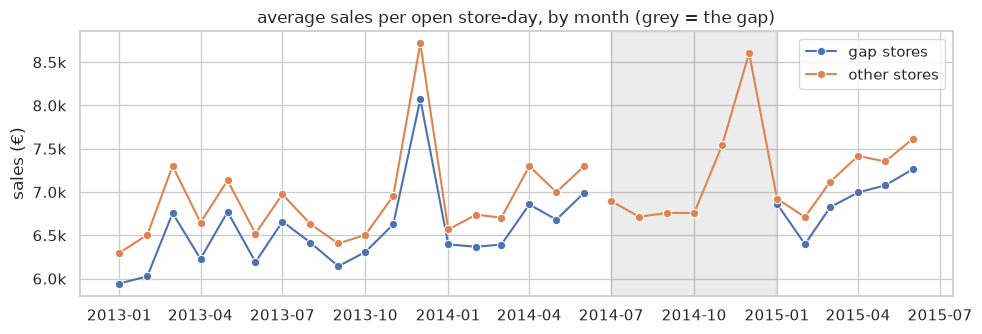

In [74]:
monthly = (
    open_days.assign(group=np.where(open_days["store_id"].isin(gap_store_ids), "gap stores", "other stores"))
    .groupby([pd.Grouper(key="date", freq="MS"), "group"], as_index=False)["sales"].mean()
)
monthly["period"] = np.where(monthly["date"] < gap_start, "before", "after")

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.lineplot(data=monthly, x="date", y="sales", hue="group", units=monthly["group"] + monthly["period"],
             estimator=None, marker="o", ax=ax)
ax.axvspan(gap_start, gap_end, color="grey", alpha=0.15)
ax.set_title("average sales per open store-day, by month (grey = the gap)")
ax.set_xlabel("")
ax.set_ylabel("sales (€)")
ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1000:.1f}k")
ax.legend(title=None)
plt.tight_layout()
plt.show()


In [75]:
first_28_days = open_days[open_days["store_id"].isin(gap_store_ids) & open_days["date"].between("2015-01-01", "2015-01-28")]
print(f"open store-days in the 28 days after reopening: {len(first_28_days):,}")

open store-days in the 28 days after reopening: 3,966


**Insight**

**Why it matters:** these 180 stores are normal stores with six months missing. We keep them and treat the gap as missing data, not zero sales. The only cost is empty lags after they reopen.

- 180 stores (16%) have no rows from 2014-07-01 to 2014-12-31 and are back on 2015-01-01. Refurbishment is the usual theory, but a missing data feed would look the same.
- They came back at the same level: +4.1% from January to June 2014 to 2015, against +3.2% for the other stores. They sold about 4% less than the others both before and after.
- Lags are empty for up to 28 days after reopening (3,966 open store-days). LightGBM accepts that, while Ridge needs a fill or those rows dropped.


### Time series analysis

Looking at how sales move over time: the slow level (trend), the weekly pattern, and which past days predict today. We use the daily total sales of the stores that have a row for every day, so the 2014 gap block does not fake a dip.

- Decomposition: trend, weekly pattern, and noise
- Autocorrelation


#### Decomposition
We split the daily series into three parts: the trend (the slow level), the weekly pattern (the same every week), and the noise (what is left).


893 of 1115 stores have a row for every day


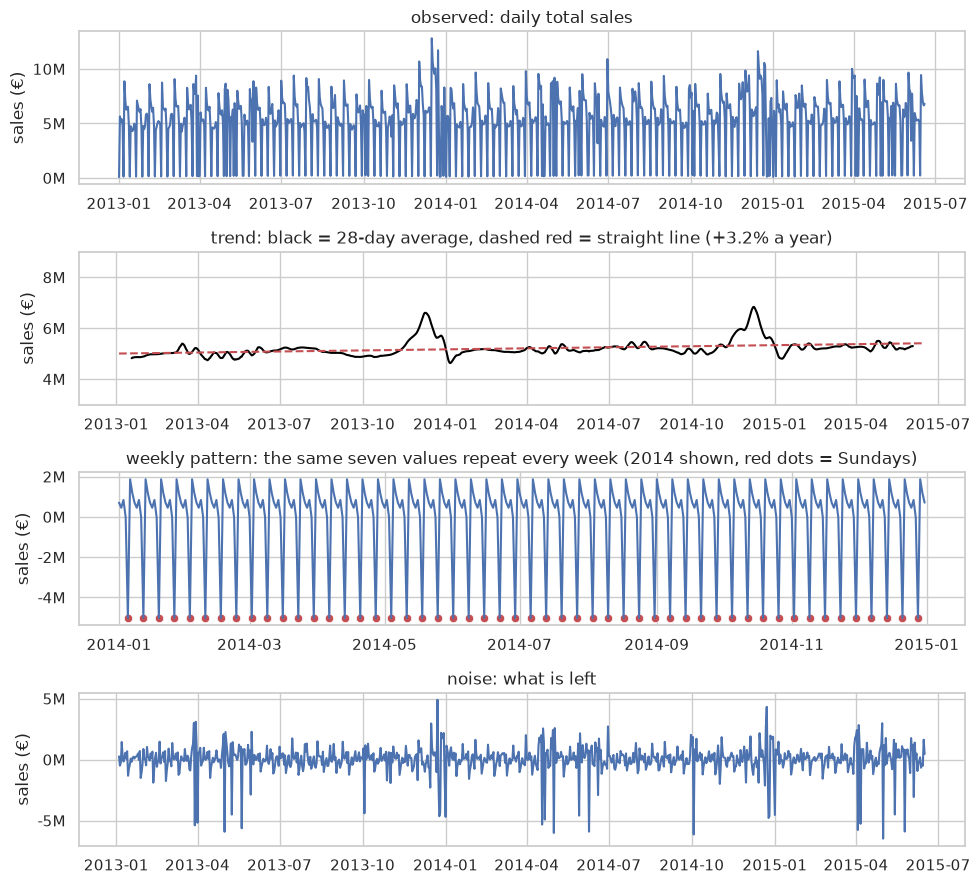

In [76]:
# one daily series from the stores that have a row for every day
n_days = (eda_df["date"].max() - eda_df["date"].min()).days + 1
days_per_store = eda_df.groupby("store_id")["date"].nunique()
complete = eda_df[eda_df["store_id"].isin(days_per_store[days_per_store == n_days].index)]
daily_sales = complete.groupby("date")["sales"].sum()
print(f"{complete['store_id'].nunique()} of {len(days_per_store)} stores have a row for every day")

decomposition = seasonal_decompose(daily_sales, model="additive", period=7)

# a straight line through the slow level, for the overall direction
trend_values = decomposition.trend.dropna()
days = (trend_values.index - trend_values.index[0]).days
slope, intercept = np.polyfit(days, trend_values, 1)

weekly_pattern = decomposition.seasonal.loc["2014-01-01":"2014-12-31"]
sundays = weekly_pattern[weekly_pattern.index.day_name() == "Sunday"]

fig, axes = plt.subplots(4, 1, figsize=(10, 9))
sns.lineplot(x=decomposition.observed.index, y=decomposition.observed, ax=axes[0])
axes[0].set_title("observed: daily total sales")
sns.lineplot(x=decomposition.trend.index, y=decomposition.trend.rolling(28, center=True).mean(), color="black", ax=axes[1])
sns.lineplot(x=trend_values.index, y=intercept + slope * days, color="#c44e52", linestyle="--", ax=axes[1])
axes[1].set_ylim(3e6, 9e6)
axes[1].set_title(f"trend: black = 28-day average, dashed red = straight line ({slope * 365 / trend_values.mean():+.1%} a year)")
sns.lineplot(x=weekly_pattern.index, y=weekly_pattern, ax=axes[2])
sns.scatterplot(x=sundays.index, y=sundays, color="#c44e52", ax=axes[2])
axes[2].set_title("weekly pattern: the same seven values repeat every week (2014 shown, red dots = Sundays)")
sns.lineplot(x=decomposition.resid.index, y=decomposition.resid, ax=axes[3])
axes[3].set_title("noise: what is left")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("sales (€)")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y / 1e6:.0f}M")
plt.tight_layout()
plt.show()


**How to read it**

- **Observed:** daily total sales of the 893 stores. A sharp weekly rhythm repeats all the way through, with a deep dip every Sunday.
- **Trend:** almost flat. A straight line rises just 3.2% a year, and the 28-day average only bumps up around Christmas.
- **Weekly pattern:** the same shape every week, and the biggest piece by far (about two thirds of the ups and downs, 66%). Monday is highest (1.9M above average), sales ease down through the week, and Sunday is the lowest (5.0M below) because most stores are closed.
- **Noise:** small on most days. The sharp dips are public holidays, when stores close, and the spikes come just before them, such as December 23.


#### Autocorrelation
Autocorrelation measures how much a day looks like the day N days before it. Tall bars show which lags carry information.


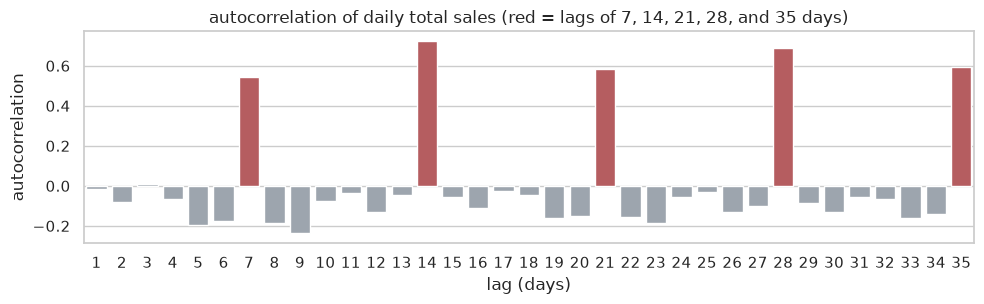

In [77]:
acf_values = acf(daily_sales, nlags=35)
lags = np.arange(1, 36)

fig, ax = plt.subplots(figsize=(10, 3.2))
sns.barplot(x=lags, y=acf_values[1:], hue=np.where(lags % 7 == 0, "multiple of 7", "other"),
            palette={"multiple of 7": "#c44e52", "other": "#9aa5b1"}, legend=False, ax=ax)
ax.set_title("autocorrelation of daily total sales (red = lags of 7, 14, 21, 28, and 35 days)")
ax.set_xlabel("lag (days)")
ax.set_ylabel("autocorrelation")
plt.tight_layout()
plt.show()


**How to read it**

- Five red bars stand out, at 7, 14, 21, 28, and 35 days. A day looks a lot like the same weekday in earlier weeks.
- The bars at 14 and 28 days (0.72 and 0.69) are taller than the ones at 7 and 21 days (0.55 and 0.58). Promos run in alternating weeks, so the same weekday two or four weeks back is usually in the same promo state.
- Between the peaks the bars sit near or below zero, so those lags carry little signal. Past 28 days nothing new appears (35 days: 0.59).


#### Insights

**Why it matters:** sales are driven by the calendar, not by a trend. The weekday sets the base level, promo weeks lift it, holidays break it, and the overall level barely moves (a straight line rises just 3.2% a year). So the model should lean on sales from 7, 14, 21, and 28 days ago, plus the promo and holiday calendar.

- **Use lags 7, 14, 21, and 28.** They are the peaks, and nothing past 28 adds more. `lag_14` and `lag_28` are the strongest, so they matter most.
- **Add the promo flag of the lag days too.** Promo days sell 38.7% more, and promo weeks alternate, so last week's sales may come from the opposite promo state.
- **Add holiday features.** Public holidays cause the deepest dips (26 of the 30 lowest days, although holidays are only 3% of all days), and the biggest highs come the day before, such as December 23. Lags cannot know about holidays.


### Feature importance analysis

Which features carry the most signal? For each raw column, we measure how much of the differences in daily sales it explains on its own (open days only).


store, weekday, and promo together explain 84.5% of the differences in daily sales


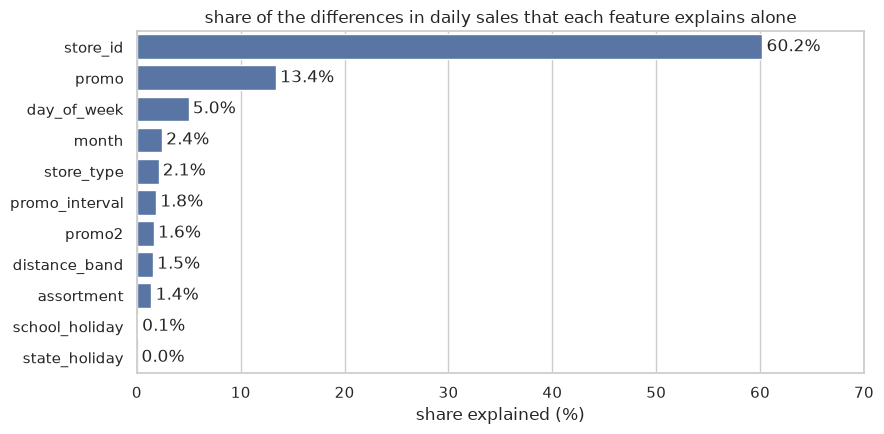

In [78]:
candidates = open_days.assign(
    month=open_days["date"].dt.month,
    distance_band=pd.qcut(open_days["competition_distance"], 10, duplicates="drop"),
)
total_spread = ((candidates["sales"] - candidates["sales"].mean()) ** 2).sum()

# share of the differences in sales that each feature explains on its own
features = ["store_id", "day_of_week", "promo", "month", "state_holiday", "school_holiday",
            "store_type", "assortment", "promo2", "promo_interval", "distance_band"]
shares = {}
for feature in features:
    group_mean = candidates.groupby(feature, observed=True)["sales"].transform("mean")
    shares[feature] = 1 - ((candidates["sales"] - group_mean) ** 2).sum() / total_spread
importance = pd.Series(shares).sort_values(ascending=False) * 100

# the three strongest together: which store, which weekday, and promo or not
group_mean = candidates.groupby(["store_id", "day_of_week", "promo"])["sales"].transform("mean")
together = 1 - ((candidates["sales"] - group_mean) ** 2).sum() / total_spread
print(f"store, weekday, and promo together explain {together:.1%} of the differences in daily sales")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=importance.values, y=importance.index, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title("share of the differences in daily sales that each feature explains alone")
ax.set_xlim(0, 70)
ax.set_xlabel("share explained (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


**How to read it**

- Each bar is how much of the day-to-day differences in sales that feature explains by itself. For example, knowing only which store it is removes 60.2% of the spread.
- One feature stands far above the rest: `store_id`. Then `promo` (13.4%) and `day_of_week` (5.0%). Everything else is below 3%.
- This ranks the raw columns only. The lag and rolling features do not exist yet, so the model-based importance will rank those.


#### Insights

- **Store level comes first.** Store identity explains 60.2% alone, so features that capture a store's own level (lags and store averages) matter most. This matches the earlier finding that a store keeps its level.
- **Store, weekday, and promo together explain 84.5%.** That holds up on months the averages were not fitted on: fitted before 2015, they explain 85.2% of January to June 2015. Weekday and promo alone explain 17.1%, less than 5.0% plus 13.4%, because promos only run Monday to Friday.
- **The rest are small helpers.** Month, store type, Promo2, distance, and assortment each explain under 3%. The raw holiday flags explain almost nothing on open days, because holiday closures are already in the closed days we remove. "Days to the next holiday" is still worth testing, because of the December 23 spike.


### Findings

- **Result:** sales are driven by which store, which weekday, and whether there is a promo (together 84.5% of the differences in daily sales). The level barely drifts (+3.2% a year), and the big swings come from the promo calendar and holidays.
- **Target:** open-day sales are right-skewed (skew 1.59) and close to symmetric after `log1p` (-0.11). We compare both in the backtest and always score in euros.
- **The 2014 gap:** 180 stores have no rows from 2014-07-01 to 2014-12-31 and came back at the same level. We treat the days as missing, not zero. Their lags are empty for up to 28 days after reopening (the first 28 days of 2013 have the same issue for every store). LightGBM accepts that, and Ridge needs a fill or those rows dropped.
- **Hand-offs to Feature Engineering:**
  - Lags 7, 14, 21, and 28 by calendar date (14 and 28 are strongest), plus rolling means.
  - `promo`, `day_of_week`, and the promo flag of the lag days.
  - Holiday features: `state_holiday`, `school_holiday`, and days to and since a holiday (the December 23 spike, the Easter and May 1 dips).
  - Store level from training rows only (store averages). Encode `store_type`, `assortment`, and `promo_interval`, and build "months open" and "Promo2 active" from the two date columns. Distance may need a log or bands for Ridge.
